<a href="https://colab.research.google.com/github/Gervonta-Davis/smartfarm-rl-control/blob/main/smartfarm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 이 데이터는 실측 데이터가 아니라 **시뮬레이터로 생성한 합성 데이터**를 사용합니다.

## 전체 흐름
| 구간 | 내용 | 예상 시간 |
|---|---|---|
| 0 | 패키지 설치 / 라이브러리 import | 1분 |
| 1 | 합성 데이터 생성 (또는 CSV 업로드) | 1분 |
| 2 | 데이터 확인 (통계, 시각화) | 즉시 |
| 3 | 강화학습 환경(Gymnasium) 정의 | 즉시 |
| 4 | 기준선(규칙 기반 제어기) 평가 | 1분 |
| 5 | PPO 학습 | 5~15분 |
| 6 | 학습 모델 vs 기준선 비교 | 1분 |
| 7 | 하루 제어 결과 시각화 | 즉시 |
| 8 | 모델 / 결과 저장 | 즉시 |




## 구간 0. 패키지 설치 및 import
- `gymnasium`: 강화학습 환경의 표준 인터페이스
- `stable-baselines3`: PPO 등 검증된 강화학습 알고리즘 구현체

In [ ]:
!pip -q install stable-baselines3 gymnasium

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO

plt.rcParams['axes.unicode_minus'] = False   # 그래프 라벨은 영문으로 표기(코랩 한글 폰트 문제 회피)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 5.9 MB/s eta 0:00:00


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 구간 1. 합성 데이터 생성
- 외기(온도·일사량)는 계절·일변화·날씨 잡음으로 생성합니다.
- 온실 내부 온도·습도·CO2는 1차 동역학 모델로 계산하고, 설비 작동은 규칙 기반 제어기 + 잡음으로 만듭니다.
- 결과는 `synthetic_smartfarm_2025.csv`로 저장됩니다 (52,560행, 10분 간격, 1년치).
- 이미 CSV가 있다면 이 셀을 건너뛰고 왼쪽 파일 패널에 업로드하세요.

In [ ]:
"""
합성(시뮬레이션) 스마트팜 데이터 생성기
- 실측 데이터가 아니라, 단순 물리 모델 + 규칙 기반 제어기로 생성한 데이터입니다.
- 논문에는 반드시 '시뮬레이터로 생성한 합성 데이터'임을 명시하세요.
"""
import numpy as np, pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)
DT_MIN = 10                                   # 샘플링 간격(분)
idx = pd.date_range("2025-01-01", "2025-12-31 23:50", freq=f"{DT_MIN}min")
N = len(idx)
doy = idx.dayofyear.values
hour = idx.hour.values + idx.minute.values / 60

# ---------- 외기 환경 ----------
t_season = -np.cos(2 * np.pi * (doy - 15) / 365)             # 1월 최저, 7월 최고
T_out_mean = 12.5 + 14 * t_season * 0.9
diurnal = 4.5 * np.sin(2 * np.pi * (hour - 9) / 24)
weather = np.zeros(N); w = 0.0                               # 날씨 AR(1) 잡음
for i in range(N):
    w = 0.995 * w + rng.normal(0, 0.12); weather[i] = w
T_out = T_out_mean + diurnal + 2.0 * weather

# 일사량(W/m2): 태양고도 근사 x 구름
decl = 23.45 * np.sin(np.radians(360 * (284 + doy) / 365))
lat = 36.6
ha = (hour - 12) * 15
sin_el = (np.sin(np.radians(lat)) * np.sin(np.radians(decl)) +
          np.cos(np.radians(lat)) * np.cos(np.radians(decl)) * np.cos(np.radians(ha)))
clear = np.clip(sin_el, 0, None) * 900
cloud = np.clip(0.75 - 0.35 * weather + rng.normal(0, 0.05, N), 0.1, 1.0)
solar = clear * cloud

# ---------- 목표 환경(주/야) ----------
is_day = solar > 20
T_set = np.where(is_day, 24.0, 17.0)
H_set = np.where(is_day, 70.0, 80.0)
C_set = np.where(is_day, 800.0, 450.0)

# ---------- 설비 정의 ----------
dev = ["냉난방기", "유동팬", "분무기", "보광등", "보조난방기", "CO2동작",
       "좌천창", "우천창", "커튼1", "커튼2", "커튼3"]
rated_kw = dict(zip(dev, [5.5, 0.4, 0.3, 3.0, 4.0, 0.1, 0.15, 0.15, 0.1, 0.1, 0.1]))

Tin, Hin, Cin = 18.0, 75.0, 450.0
out = {k: np.zeros(N) for k in ["T_in", "H_in", "CO2_in"]}
act = {d: np.zeros(N) for d in dev}
clip01 = lambda x: float(np.clip(x, 0, 1))

for i in range(N):
    eT, eH, eC = T_set[i] - Tin, H_set[i] - Hin, C_set[i] - Cin
    day = is_day[i]
    # 규칙 기반 제어기 + 운영자 변동성(잡음)
    heat = clip01(eT / 6) if eT > 0 else 0
    cool = clip01(-eT / 5) if eT < -1 else 0
    hvac = clip01((heat if heat > 0 else cool) + rng.normal(0, 0.04)) if (heat or cool) else 0
    aux = clip01((eT - 3) / 4) if (eT > 3 and T_out[i] < 5) else 0
    vent = clip01((-eT - 0.5) / 4 + (0.3 if Hin > 88 else 0)) if (-eT > 0.5 or Hin > 88) else 0
    sideL = clip01(vent + rng.normal(0, 0.05)) if vent else 0
    sideR = clip01(vent * 0.9 + rng.normal(0, 0.05)) if vent else 0
    fan = clip01(0.3 + 0.4 * vent + (0.2 if Hin > 85 else 0)) if (day or Hin > 85) else 0.1 * (rng.random() < 0.3)
    spray = clip01(eH / 20) if (day and eH > 5 and Tin > 22) else 0
    light = 1.0 if (day and solar[i] < 120 and 6 <= hour[i] <= 18) else 0
    co2 = clip01(eC / 400) if (day and eC > 50 and vent < 0.3) else 0
    cur1 = 1.0 if (day and solar[i] > 650) else 0                  # 차광
    cur2 = 1.0 if (not day and T_out[i] < 8) else 0                # 보온
    cur3 = 1.0 if (not day and T_out[i] < 0) else 0
    vals = [hvac, fan, spray, light, aux, co2, sideL, sideR, cur1, cur2, cur3]
    for d, v in zip(dev, vals): act[d][i] = round(v, 3)

    # ---------- 온실 상태 전이(1차 동역학) ----------
    k_wall = 0.010 * (1 - 0.35 * cur2 - 0.2 * cur3)
    k_vent = 0.045 * (sideL + sideR) / 2 + 0.006 * fan
    gain_solar = 0.0030 * solar[i] * (1 - 0.4 * cur1) + 0.0008 * light * 400 * 0.1
    hv = 0.55 * heat * (hvac if heat else 0) - 0.55 * (hvac if (cool and not heat) else 0)
    dT = (k_wall + k_vent) * (T_out[i] - Tin) + gain_solar + 1.6 * hv + 0.9 * aux
    Tin += dT + rng.normal(0, 0.05)

    H_out_ref = 70 - 0.8 * (T_out[i] - 15)
    dH = (0.015 + k_vent) * (H_out_ref - Hin) + 6.0 * spray - 0.35 * max(dT, 0) * 4 \
         + (0.4 if day else 0.0) + rng.normal(0, 0.15)
    Hin = float(np.clip(Hin + dH, 30, 99))

    photo = 0.9 * (solar[i] / 800) * (Cin / 600) if day else 0
    dC = (0.01 + 3 * k_vent) * (420 - Cin) + 60 * co2 - 25 * photo + (4 if not day else 0) + rng.normal(0, 3)
    Cin = float(np.clip(Cin + dC, 300, 1800))

    out["T_in"][i], out["H_in"][i], out["CO2_in"][i] = Tin, Hin, Cin

df = pd.DataFrame({"datetime": idx, "외기온도": T_out.round(2), "일사량": solar.round(1),
                   "내부온도": out["T_in"].round(2), "내부습도": out["H_in"].round(1),
                   "CO2농도": out["CO2_in"].round(0),
                   "목표온도": T_set, "목표습도": H_set, "목표CO2": C_set})
for d in dev: df[d] = act[d]
# 전력량(kWh): 스텝 사용량 → 일 단위 누적
date = idx.date
for d in dev:
    step = act[d] * rated_kw[d] * DT_MIN / 60
    df[f"{d}_전력누적"] = pd.Series(step).groupby(date).cumsum().round(3).values
df["총전력누적"] = df[[f"{d}_전력누적" for d in dev]].sum(axis=1).round(3)
df.to_csv("synthetic_smartfarm_2025.csv", index=False, encoding="utf-8-sig")
print(df.shape)

(52560, 32)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 구간 2. 데이터 확인
- 생성된 데이터의 분포와 하루 패턴이 상식적인지 확인합니다.
- 여름·겨울 하루를 골라 환경 변화와 설비 작동을 시각화합니다.

(52560, 32)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,외기온도,일사량,내부온도,내부습도,CO2농도
count,52560.0,52560.0,52560.0,52560.0,52560.0
mean,12.5,148.1,21.7,73.6,545.4
std,10.3,213.8,5.8,7.7,121.6
min,-11.6,0.0,14.1,56.7,305.0
25%,3.6,0.0,16.6,66.4,437.0
50%,12.3,0.0,19.6,73.1,559.0
75%,21.2,264.0,26.4,80.8,648.0
max,35.4,876.3,40.5,93.6,758.0


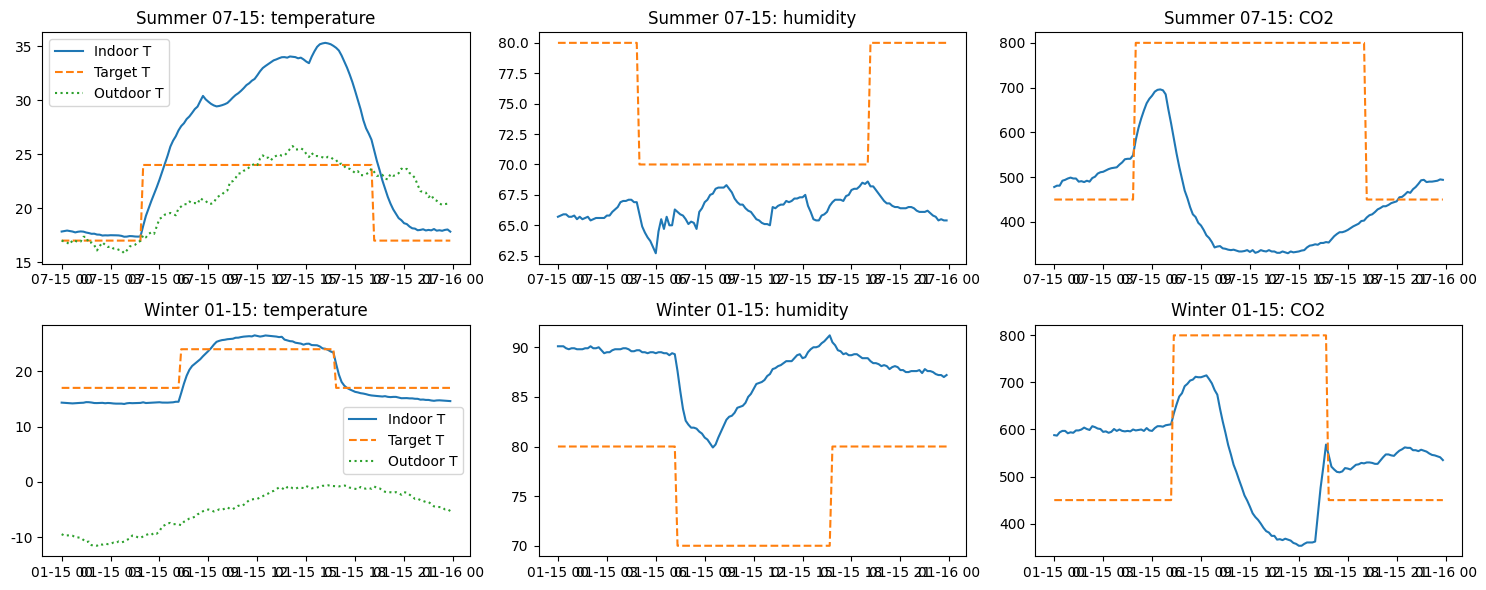

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
df = pd.read_csv('synthetic_smartfarm_2025.csv', parse_dates=['datetime'])
print(df.shape)
display(df[['외기온도','일사량','내부온도','내부습도','CO2농도']].describe().round(1))

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for r, (name, day) in enumerate([('Summer 07-15', '2025-07-15'), ('Winter 01-15', '2025-01-15')]):
    d = df[df.datetime.dt.strftime('%Y-%m-%d') == day]
    axes[r,0].plot(d.datetime, d['내부온도'], label='Indoor T'); axes[r,0].plot(d.datetime, d['목표온도'], '--', label='Target T')
    axes[r,0].plot(d.datetime, d['외기온도'], ':', label='Outdoor T'); axes[r,0].set_title(f'{name}: temperature'); axes[r,0].legend()
    axes[r,1].plot(d.datetime, d['내부습도']); axes[r,1].plot(d.datetime, d['목표습도'], '--'); axes[r,1].set_title(f'{name}: humidity')
    axes[r,2].plot(d.datetime, d['CO2농도']); axes[r,2].plot(d.datetime, d['목표CO2'], '--'); axes[r,2].set_title(f'{name}: CO2')
plt.tight_layout(); plt.show()

## 구간 3. 강화학습 환경 정의
논문의 설계를 그대로 구현한 부분입니다.

| 요소 | 구현 |
|---|---|
| **상태(입력)** | 내부 온도·습도·CO2, 외기온도, 일사량, 목표값, 목표와의 오차, 시각(sin/cos) → 13차원 |
| **행동(출력)** | 11개 설비의 작동 비율·강도 (0~1 실수값) |
| **보상** | −(목표와의 오차) − `energy_coef` × (사용 전력량) → 목표 도달 + 에너지 효율을 동시에 반영 |
| **에피소드** | 하루(144 스텝 = 10분 × 144) |
| **외기 조건** | 데이터의 실제(합성) 외기온도·일사량을 그대로 재생 |
| **전이 모델** | 구간 1의 온실 동역학과 같은 구조(소음 포함). 냉난방기는 `목표−현재` 부호로 난방/냉방 방향이 자동 결정되고, 행동은 세기만 정함 |

- 학습/평가 분리: 365일 중 80%의 날을 학습용, 20%를 평가용으로 무작위 분할합니다 (`seed` 고정).
- `energy_coef`를 키우면 에너지 절감을 더 중시하는 정책이 학습됩니다 (논문의 trade-off 실험에 활용 가능).

In [ ]:
DEV = ['냉난방기','유동팬','분무기','보광등','보조난방기','CO2동작','좌천창','우천창','커튼1','커튼2','커튼3']
RATED_KW = np.array([5.5, 0.4, 0.3, 3.0, 4.0, 0.1, 0.15, 0.15, 0.1, 0.1, 0.1], dtype=np.float32)
DT_MIN = 10
STEPS_PER_DAY = 144


class SmartFarmEnv(gym.Env):
    def __init__(self, df, day_pool=None, energy_coef=0.3, seed=0):
        super().__init__()
        self.T_out = df['외기온도'].values
        self.solar = df['일사량'].values
        self.hour = (df['datetime'].dt.hour + df['datetime'].dt.minute / 60).values
        self.init_T = df['내부온도'].values; self.init_H = df['내부습도'].values; self.init_C = df['CO2농도'].values
        self.N = len(df)
        self.n_days = self.N // STEPS_PER_DAY
        self.day_pool = np.arange(self.n_days) if day_pool is None else np.asarray(day_pool)
        self.energy_coef = energy_coef
        self.rng = np.random.default_rng(seed)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(13,), dtype=np.float32)
        self.action_space = spaces.Box(0.0, 1.0, shape=(len(DEV),), dtype=np.float32)

    # ---- 목표 환경 (낮/밤) ----
    def targets(self, i):
        day = self.solar[i] > 20
        return (24.0, 70.0, 800.0) if day else (17.0, 80.0, 450.0)

    def state(self):
        i = min(self.i, self.N - 1)
        Ts, Hs, Cs = self.targets(i)
        return dict(T=self.T, H=self.H, C=self.C, T_out=self.T_out[i], solar=self.solar[i],
                    hour=self.hour[i], Ts=Ts, Hs=Hs, Cs=Cs)

    def _obs(self):
        s = self.state(); h = s['hour']
        return np.array([s['T']/40, s['H']/100, s['C']/1000, s['T_out']/40, s['solar']/900,
                         s['Ts']/40, s['Hs']/100, s['Cs']/1000,
                         (s['Ts']-s['T'])/10, (s['Hs']-s['H'])/30, (s['Cs']-s['C'])/500,
                         np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24)], dtype=np.float32)

    def reset(self, seed=None, options=None):
        if seed is not None: self.rng = np.random.default_rng(seed)
        d = int(self.rng.choice(self.day_pool))
        self.i0 = d * STEPS_PER_DAY; self.i = self.i0; self.t = 0
        self.T, self.H, self.C = float(self.init_T[self.i]), float(self.init_H[self.i]), float(self.init_C[self.i])
        return self._obs(), {}

    def step(self, action):
        a = np.clip(np.asarray(action, dtype=np.float32), 0, 1)
        hvac, fan, spray, light, aux, co2, sL, sR, c1, c2, c3 = [float(x) for x in a]
        s = self.state(); T, H, C = self.T, self.H, self.C
        day = s['solar'] > 20

        # --- 온실 동역학 ---
        hv = 0.55 * hvac if s['Ts'] - T > 0 else -0.55 * hvac       # 난방(+) / 냉방(-)
        vent = (sL + sR) / 2
        k_wall = 0.010 * (1 - 0.35 * c2 - 0.2 * c3)
        k_vent = 0.045 * vent + 0.006 * fan
        gain = 0.0030 * s['solar'] * (1 - 0.4 * c1) + 0.032 * light
        dT = (k_wall + k_vent) * (s['T_out'] - T) + gain + 1.6 * hv + 0.9 * aux
        H_ref = 70 - 0.8 * (s['T_out'] - 15)
        dH = (0.015 + k_vent) * (H_ref - H) + 6.0 * spray - 1.4 * max(dT, 0) + (0.4 if day else 0.0)
        photo = 0.9 * (s['solar'] / 800) * (C / 600) if day else 0.0
        dC = (0.01 + 3 * k_vent) * (420 - C) + 60 * co2 - 25 * photo + (0 if day else 4)

        self.T = float(np.clip(T + dT + self.rng.normal(0, 0.05), -10, 50))
        self.H = float(np.clip(H + dH + self.rng.normal(0, 0.15), 30, 99))
        self.C = float(np.clip(C + dC + self.rng.normal(0, 3), 300, 1800))

        # --- 보상 ---
        kwh = float(np.sum(a * RATED_KW) * DT_MIN / 60)
        eT, eH, eC = abs(self.T - s['Ts']), abs(self.H - s['Hs']), abs(self.C - s['Cs'])
        track = eT / 2 + 0.5 * eH / 10 + 0.5 * eC / 200
        reward = -(track + self.energy_coef * kwh)

        self.i += 1; self.t += 1
        truncated = self.t >= STEPS_PER_DAY
        info = dict(T=self.T, H=self.H, C=self.C, eT=eT, eH=eH, eC=eC, kwh=kwh, Ts=s['Ts'])
        return self._obs(), reward, False, truncated, info


# 학습/평가 날짜 분할 (80 : 20)
n_days = len(df) // STEPS_PER_DAY
perm = np.random.default_rng(42).permutation(n_days)
train_days, test_days = perm[: int(n_days*0.8)], perm[int(n_days*0.8):]
print('train days:', len(train_days), '/ test days:', len(test_days))

train days: 292 / test days: 73


## 구간 4. 기준선: 규칙 기반 제어기 + 평가 함수
- 현재 스마트팜에서 흔히 쓰는 "if 온도가 목표보다 높으면 환기…" 형태의 규칙 제어기입니다.
- 강화학습 모델이 이 기준선보다 **오차가 작고 에너지를 덜 쓰는지** 비교하는 것이 실험의 핵심입니다.
- 평가 지표: 평균 절대 오차(온도·습도·CO2), 하루 전력량(kWh), 온도가 목표 ±1℃ 안에 있던 시간 비율, 평균 보상

In [ ]:
clip01 = lambda x: float(np.clip(x, 0, 1))

def rule_policy(env, obs):
    s = env.state(); T, H, C = s['T'], s['H'], s['C']
    day = s['solar'] > 20
    eT, eH, eC = s['Ts']-T, s['Hs']-H, s['Cs']-C
    heat = clip01(eT/6) if eT > 0 else 0
    cool = clip01(-eT/5) if eT < -1 else 0
    hvac = max(heat, cool)
    aux = clip01((eT-3)/4) if (eT > 3 and s['T_out'] < 5) else 0
    vent = clip01((-eT-0.5)/4 + (0.3 if H > 88 else 0)) if (-eT > 0.5 or H > 88) else 0
    fan = clip01(0.3 + 0.4*vent + (0.2 if H > 85 else 0)) if (day or H > 85) else 0
    spray = clip01(eH/20) if (day and eH > 5 and T > 22) else 0
    light = 1.0 if (day and s['solar'] < 120 and 6 <= s['hour'] <= 18) else 0
    co2 = clip01(eC/400) if (day and eC > 50 and vent < 0.3) else 0
    c1 = 1.0 if (day and s['solar'] > 650) else 0
    c2 = 1.0 if ((not day) and s['T_out'] < 8) else 0
    c3 = 1.0 if ((not day) and s['T_out'] < 0) else 0
    return np.array([hvac, fan, spray, light, aux, co2, vent, vent*0.9, c1, c2, c3], dtype=np.float32)


def evaluate(policy_fn, days, energy_coef=0.3, n_episodes=None, seed=123):
    env = SmartFarmEnv(df, day_pool=days, energy_coef=energy_coef, seed=seed)
    n_episodes = n_episodes or len(days)
    rows = []
    for ep in range(n_episodes):
        obs, _ = env.reset()
        tot_r, ek, eT_l, eH_l, eC_l, kwh = 0, 0, [], [], [], 0
        done = False
        while not done:
            obs, r, term, trunc, info = env.step(policy_fn(env, obs))
            tot_r += r; kwh += info['kwh']
            eT_l.append(info['eT']); eH_l.append(info['eH']); eC_l.append(info['eC'])
            done = term or trunc
        rows.append(dict(reward=tot_r, MAE_T=np.mean(eT_l), MAE_H=np.mean(eH_l), MAE_CO2=np.mean(eC_l),
                         kWh_per_day=kwh, T_in_band=np.mean(np.array(eT_l) <= 1.0)))
    return pd.DataFrame(rows).mean().round(3)


rule_result = evaluate(rule_policy, test_days)
random_result = evaluate(lambda env, obs: env.action_space.sample(), test_days)
print('Rule-based baseline:\n', rule_result, '\n')
print('Random policy (참고용 하한선):\n', random_result)

Rule-based baseline:
 reward        -270.912
MAE_T            1.886
MAE_H            6.403
MAE_CO2        199.812
kWh_per_day     56.956
T_in_band        0.488
dtype: float64 

Random policy (참고용 하한선):
 reward        -698.898
MAE_T            5.620
MAE_H           22.653
MAE_CO2        226.237
kWh_per_day    165.811
T_in_band        0.348
dtype: float64


## 구간 5. PPO 학습
- 학습용 날짜(`train_days`)에서 하루 단위 에피소드를 반복하며 정책을 학습합니다.
- `total_timesteps=300_000` ≈ 약 2,000일 분량 경험. 코랩 CPU 기준 5~15분.
- 학습 로그의 `ep_rew_mean`이 점차 올라가면(덜 음수) 학습이 진행되는 것입니다.
- 하이퍼파라미터(학습률, 보상 계수 `energy_coef`)를 바꿔 비교 실험을 하면 논문 분량이 풍부해집니다.

In [ ]:
ENERGY_COEF = 0.3                     # 에너지 절감 가중치 (0.1 / 0.3 / 0.6 등으로 바꿔 비교 가능)
train_env = SmartFarmEnv(df, day_pool=train_days, energy_coef=ENERGY_COEF, seed=0)

model = PPO('MlpPolicy', train_env, learning_rate=3e-4, n_steps=2048, batch_size=256,
            gamma=0.99, policy_kwargs=dict(net_arch=[128, 128]), seed=0, verbose=1)
model.learn(total_timesteps=300_000)

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 144      |
|    ep_rew_mean     | -803     |
| time/              |          |
|    fps             | 1875     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 144          |
|    ep_rew_mean          | -888         |
| time/                   |              |
|    fps                  | 1512         |
|    iterations           | 2            |
|    time_elapsed         | 2            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0074749757 |
|    clip_fraction        | 0.0824       |
|    clip_range           | 0.2          |
|    entropy_loss         | -15.6        |
|    explained_variance   | -0.00204     |
|    learning_rate        | 0.0003       |
|    loss                 | 5.56e+03     |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.0112      |
|    std                  | 0.999        |
|    value_loss           | 1.11e+04     |
------------------------------------------
------------------------------------------
| rollout/ 

## 구간 6. 학습 모델 vs 기준선 비교
- 평가용 날짜(`test_days`, 학습에 쓰이지 않은 날)에서 같은 조건으로 비교합니다.
- 논문의 결과 표로 그대로 활용할 수 있습니다.

In [ ]:
ppo_policy = lambda env, obs: model.predict(obs, deterministic=True)[0]
ppo_result = evaluate(ppo_policy, test_days, energy_coef=ENERGY_COEF)

comparison = pd.DataFrame({'Rule-based': rule_result, 'PPO (proposed)': ppo_result, 'Random': random_result})
comparison['PPO vs Rule (%)'] = ((comparison['PPO (proposed)'] / comparison['Rule-based'] - 1) * 100).round(1)
display(comparison)

,Rule-based,PPO (proposed),Random,PPO vs Rule (%)
reward,-270.912,-205.543,-698.898,-24.1
MAE_T,1.886,0.946,5.620,-49.8
MAE_H,6.403,7.366,22.653,15.0
MAE_CO2,199.812,144.582,226.237,-27.6
kWh_per_day,56.956,107.878,165.811,89.4
T_in_band,0.488,0.796,0.348,63.1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 구간 7. 하루 제어 결과 시각화
- 같은 날(평가용)을 두 제어기가 어떻게 다르게 제어했는지 비교합니다. 논문의 그림으로 사용할 수 있습니다.
- `DAY_INDEX`를 바꾸면 다른 날을 볼 수 있습니다.

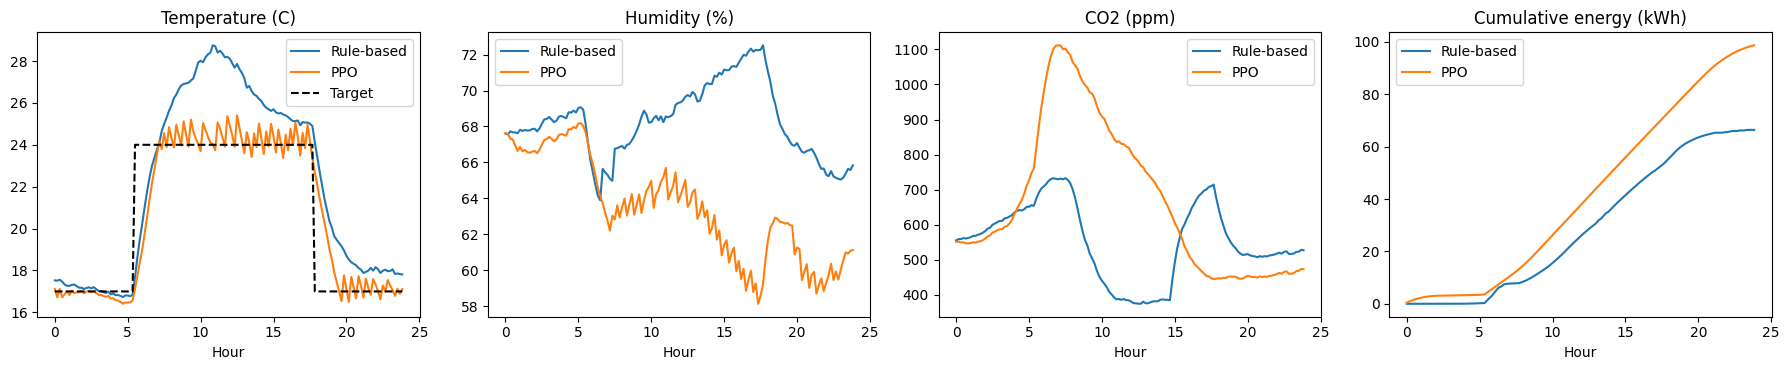

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
def rollout(policy_fn, day, energy_coef=ENERGY_COEF):
    env = SmartFarmEnv(df, day_pool=[day], energy_coef=energy_coef, seed=0)
    obs, _ = env.reset(); log = []; done = False
    while not done:
        a = policy_fn(env, obs); obs, r, term, trunc, info = env.step(a)
        log.append({**info, 'Ts': info['Ts']}); done = term or trunc
    out = pd.DataFrame(log); out['kWh_cum'] = out['kwh'].cumsum(); return out

DAY_INDEX = int(test_days[0])
roll_rule = rollout(rule_policy, DAY_INDEX); roll_ppo = rollout(ppo_policy, DAY_INDEX)
x = np.arange(STEPS_PER_DAY) * DT_MIN / 60

fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for a_, col, ttl in zip(ax[:3], ['T','H','C'], ['Temperature (C)', 'Humidity (%)', 'CO2 (ppm)']):
    a_.plot(x, roll_rule[col], label='Rule-based'); a_.plot(x, roll_ppo[col], label='PPO')
    if col == 'T': a_.plot(x, roll_ppo['Ts'], 'k--', label='Target')
    a_.set_title(ttl); a_.set_xlabel('Hour'); a_.legend()
ax[3].plot(x, roll_rule['kWh_cum'], label='Rule-based'); ax[3].plot(x, roll_ppo['kWh_cum'], label='PPO')
ax[3].set_title('Cumulative energy (kWh)'); ax[3].set_xlabel('Hour'); ax[3].legend()
plt.tight_layout(); plt.show()

## 구간 8. 모델 / 결과 저장
- 코랩 런타임은 종료되면 파일이 사라집니다. 필요한 파일을 구글 드라이브에 저장하세요.

In [ ]:
import os, shutil
from google.colab import files

save_dir = '/content/smartfarm_rl_results'
os.makedirs(save_dir, exist_ok=True)

model.save(f'{save_dir}/ppo_smartfarm')                                   # 학습된 PPO 모델 (.zip 자동 생성)
comparison.to_csv(f'{save_dir}/comparison.csv', encoding='utf-8-sig')     # 제어기 비교표
df.to_csv(f'{save_dir}/synthetic_smartfarm_2025.csv', index=False, encoding='utf-8-sig')  # 사용한 합성 데이터
fig.savefig(f'{save_dir}/day_comparison.png', dpi=200, bbox_inches='tight')  # 구간 7의 하루 제어 비교 그림

shutil.make_archive('/content/smartfarm_rl_results', 'zip', save_dir)     # 하나의 zip으로 묶기
files.download('/content/smartfarm_rl_results.zip')                       # 내 컴퓨터로 다운로드
print('saved & downloaded')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

saved & downloaded
